# Домашнее задание 2. Вариант NLP: NER - детекция в тексте

**Дедлайн:** вс 22.11.2026, 23:59

В ДЗ2 вы выбираете **один** вариант: CV (детекция объектов на YOLO) или NLP (этот ноутбук). Номера задач и баллы в вариантах совпадают. NER (named entity recognition) - это детекция в тексте: найти спаны, т.е. непрерывные куски из слов, и для каждого предсказать тип сущности. Вы берете предобученный энкодер с Hugging Face Hub, находите свой датасет, приводите разметку к формату модели, дообучаете, считаете метрики и разбираете ошибки.

- Заполняйте места с `# ваш код` и ячейки «**Ответ:**». Сигнатуры функций и открытые тесты не меняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при проверке будут и другие входы
- В ответах опирайтесь на свои числа: наблюдение, объяснение, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация разметки + тесты), 3.1 (словарный бейзлайн), 5.1 (категоризация ошибок). Для обучения и стандартных метрик можно `transformers` (`Trainer` или свой цикл) и `seqeval`
- `FAST_MODE = True` - отладка на маленьком подмножестве, весь ноутбук не дольше 5 минут на T4. Финальный прогон - с `FAST_MODE = False`, ориентир до ~1 часа на T4. Бонусы включаются через `BONUS_TASKS`, выключенные бонусы пропускаются, даже если их ячейки пустые
- Запуск: Colab (T4) или Kaggle (GPU T4, ноутбук сам берет одну карту). Зависимости ставит первая ячейка, пины те же, что в `requirements_nlp.txt`. Укажите устройство в ячейке ниже, время обучения возвращает ваш `train_ner` (4.1)
- Только открытые модели и данные. Лицензию модели и датасета укажите в 1.1 и 2.1
- Можно документацию, материалы курса и код семинаров - укажите источник
- Сдача как в ДЗ1: PR в свой публичный GitHub-репозиторий, ссылка на него - в Google-форму (ссылку на форму дадим отдельно). В PR - ноутбук с outputs и `artifacts/metrics.json` (пишется в 5.3, перед бонусами). Датасет (`data/`), `runs/` и веса моделей не кладите, достаточно кода скачивания; файл доразметки из 6.1 - кладите
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs. Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что получилось. Ошибки не скрывайте: баллы ставятся по задачам, одна ошибка не обнуляет остальные
- ДЗ индивидуальное

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и ревизия · 1.2 архитектура | 4 |
| 2. Данные | 2.1 датасет · 2.2 формат разметки | 4 |
| 3. Бейзлайн | 3.1 бейзлайн до дообучения | 2 |
| 4. Дообучение | 4.1 обучение · 4.2 метрики | 6 |
| 5. Анализ | 5.1 разбор ошибок · 5.2 абляция · 5.3 выводы | 4 |
| 6*. Бонусы | 6.1 доразметка · 6.2 другая модель · 6.3 сдвиг · 6.4 экспорт и скорость · 6.5 пороги | до +4 из 5.5 |
| итого | | 20 + 4 |

Соответствие с CV-вариантом - задачи те же, меняется «геометрия»: вместо прямоугольника на картинке - отрезок из слов в предложении.

| CV (детекция на картинке) | NLP (NER в тексте) |
|---|---|
| бокс | спан: (начало, конец, тип) в индексах слов |
| класс объекта | тип сущности (PER, ORG, LOC, ...) |
| фон | тег `O` |
| VOC / COCO -> YOLO-формат | слова и спаны -> BIO-теги под сабворды токенизатора |
| backbone -> neck -> head | эмбеддинги -> слои энкодера -> голова token classification |
| mAP по IoU | F1 по сущностям (`seqeval`, спан засчитывается при точном совпадении границ и типа) |
| ошибка локализации (IoU 0.1-0.5) | ошибка границы спана (тип верный, спаны пересекаются) |
| ошибка класса | ошибка типа |
| пропуск / лишний бокс | пропуск / лишний спан |
| порог conf | порог уверенности спана |

Внутренности трансформера (attention, устройство слоя энкодера) - тема ДЗ3. Здесь энкодер рассматривается на уровне блоков.

Примерный план: первая неделя - разделы 1-3 (модель, датасет, разметка, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство (Colab T4 / Kaggle / свое), выбранные модель и датасет (ссылка и лицензия), бонусы, внешние источники и нерешенные задачи (если есть).

**Ответ:** 

In [1]:
# Зависимости (пины те же, что в requirements_nlp.txt). Запускайте эту ячейку первой, тогда перезапуск сессии не нужен
# Безвредный шум: строки ERROR от pip про bigframes / cudf / pyarrow на Kaggle и предупреждение про HF_TOKEN ниже (токен не нужен)
# Локально: сначала torch под свою платформу (https://pytorch.org/get-started/locally/)
%pip install -q "torch>=2.4" "transformers==5.22.1" "datasets==5.1.0" "accelerate==1.15.0" "seqeval==1.2.2" numpy matplotlib

/Users/paveltischenko/dl_2026_j3310_ai/.venv/bin/python: No module named pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')   # одна GPU: на Kaggle T4 x2 иначе Trainer включит DataParallel (медленнее и хуже)
import collections
import copy
import json
import math
import random
import re
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

import datasets
import transformers
from datasets import DatasetDict, load_dataset
from huggingface_hub import HfApi
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from transformers import (AutoModelForTokenClassification, AutoTokenizer, DataCollatorForTokenClassification,
                          Trainer, TrainingArguments)

transformers.logging.set_verbosity_error()
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

print(f'torch {torch.__version__}, transformers {transformers.__version__}, datasets {datasets.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')

/Users/paveltischenko/dl_2026_j3310_ai/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1111 15:38:56.198000 57574 torch/distributed/elastic/multiprocessing/redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


torch 2.11.0, transformers 5.22.1, datasets 5.1.0
CUDA available: False


In [3]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    transformers.set_seed(seed)


device = get_device()
DEVICE_NAME = torch.cuda.get_device_name(0) if device.type == 'cuda' else device.type
set_seed(0)
print(device, DEVICE_NAME)

mps mps


In [4]:
FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = set()   # например {'6.3', '6.5'}; пустое множество отключает все бонусы
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
N_TRAIN = 2000 if FAST_MODE else None   # None - весь train
N_EVAL = 500 if FAST_MODE else None     # подмножество validation и test в FAST_MODE
EPOCHS = 1 if FAST_MODE else 3
MAX_LENGTH = 128                        # длина в сабвордах, длиннее - обрезается
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)
RUN_TIMES = {}

In [5]:
# Apple Silicon (свое устройство): GPU делит 16 ГБ памяти с системой. Без лимита кэш MPS-аллокатора разрастается
# сверх физической памяти, и Metal падает с Insufficient Memory, а обучение зависает без исключения.
# С лимитом переполнение дает обычное исключение RuntimeError (см. также MICRO_BATCH в 4.1)
if device.type == 'mps':
    torch.mps.set_per_process_memory_fraction(0.75)   # доля от recommended_max_memory
    print(f'MPS: лимит {0.75 * torch.mps.recommended_max_memory() / 2**30:.1f} ГБ')

MPS: лимит 8.9 ГБ


---
# 1. Модель

## 1.1 Модель и ревизия (1.5 балла)

Выберите предобученный энкодер на Hugging Face Hub, подходящий под язык и домен вашего датасета. Модель на Hub - это git-репозиторий: владелец может перезалить веса, токенизатор или конфиг, и `main` начнет указывать на другую версию. Поэтому зафиксируйте `revision` - полный commit hash (40 символов). Его видно во вкладке «Files and versions» -> «History» или через `HfApi().model_info(MODEL_ID).sha`.

Ориентиры для выбора (не исчерпывающий список):
- русский: `cointegrated/rubert-tiny2` (29M параметров, быстрый), `DeepPavlov/rubert-base-cased` (~180M)
- многоязычные: `FacebookAI/xlm-roberta-base` (~280M), `google-bert/bert-base-multilingual-cased` (~180M), `distilbert/distilbert-base-multilingual-cased`
- английский: `google-bert/bert-base-cased`, `FacebookAI/roberta-base` (в 1.1 задайте `TOKENIZER_KWARGS = {'add_prefix_space': True}`), `microsoft/deberta-v3-small`
- биомедицина: `dmis-lab/biobert-base-cased-v1.2`

Нужен fast-токенизатор: `word_ids()`, без которого не выровнять метки по сабвордам, есть только у него. На T4 модель до ~300M параметров дообучается на датасете в десятки тысяч предложений за минуты - десятки минут.

Нужен базовый энкодер, а не модель, уже дообученная на NER: с ней 3.1 и 4.1 теряют смысл.

In [6]:
MODEL_ID = 'DeepPavlov/rubert-base-cased'
REVISION = '4036cab694767a299f2b9e6492909664d9414229'
TOKENIZER_KWARGS = {}   # для roberta-base: {'add_prefix_space': True}

In [7]:
assert MODEL_ID, 'укажите MODEL_ID'
assert re.fullmatch(r'[0-9a-f]{40}', REVISION or ''), 'REVISION - полный commit hash из 40 символов, а не main и не тег'
info = HfApi().model_info(MODEL_ID, revision=REVISION, files_metadata=True)
card = info.card_data.to_dict() if info.card_data else {}
weights = {s.rfilename: f'{s.size / 2**20:.0f} MB' for s in info.siblings if s.rfilename.endswith(('.safetensors', '.bin'))}
print(f'model:    {MODEL_ID}\nrevision: {info.sha}\nlicense:  {card.get("license")}\nlanguage: {card.get("language")}')
print(f'updated:  {info.last_modified}\nweights:  {weights}')

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION, **TOKENIZER_KWARGS)
assert tokenizer.is_fast, 'нужен fast-токенизатор: word_ids() есть только у него'
print(type(tokenizer).__name__, 'vocab size', tokenizer.vocab_size)
print(tokenizer.tokenize('Петр Ильич Чайковский родился в Воткинске'))

model:    DeepPavlov/rubert-base-cased
revision: 4036cab694767a299f2b9e6492909664d9414229
license:  None
language: ['ru']
updated:  2021-11-23 08:03:04+00:00
weights:  {'pytorch_model.bin': '681 MB'}


BertTokenizer vocab size 119547
['Петр', 'Ильич', 'Чайковский', 'родился', 'в', 'Вот', '##кинс', '##ке']


**Вопрос.** Почему вы выбрали эту модель: язык и данные предобучения, размер и скорость, ожидаемое качество на NER, лицензия? Сравните с 1-2 альтернативами из списка выше: размер, язык, скорость, качество по карточке. Что может сломаться в вашем ноутбуке через полгода, если не фиксировать `revision`?

**Ответ.** Взял `DeepPavlov/rubert-base-cased`: BERT-base (12 слоёв, hidden 768, 177.3M параметров по выводу 1.2), предобученный на русской Википедии и новостях, то есть на том же языке и в том же жанре, что Collection3. Словарь на 119 547 сабвордов собран по русскому корпусу и сохраняет регистр: `Воткинске` режется на 3 части, а в среднем по train выходит 1.09 сабворда на слово (2.1); заглавная буква — главный признак имени, поэтому cased-модель для NER принципиальна. Ориентир по качеству: в таблице NER-моделей документации DeepPavlov конфигурация `ner_rus_bert` на основе RuBERT даёт на Collection3 F1 97.6 по сущностям. Поля license в карточке на Hub нет (вывод выше: `license: None`), но в документации DeepPavlov о предобученных BERT (включая RuBERT) сказано, что модели распространяются под Apache 2.0 — на это и опираюсь. Альтернативы: `cointegrated/rubert-tiny2` (MIT, 29M параметров, веса 112 МБ против 681 МБ) в ~6 раз меньше и заметно быстрее, но у узкой модели меньше ёмкости под редкие имена и названия организаций; `FacebookAI/xlm-roberta-base` (MIT, ~280M, веса 1063 МБ) многоязычный — словарь делится между 100 языками, а модель в ~1.6 раза тяжелее при том же числе слоёв; `ai-forever/ruBert-base` (Apache-2.0) отпал из-за uncased-токенизатора, стирающего регистр. Без фиксации `revision` через полгода `main` может указать на перезалитые веса, токенизатор или конфиг: поменяются `word_ids` и выравнивание меток из 2.2, число параметров в 1.2 и все метрики, а при переименовании файлов загрузка просто упадёт.

## 1.2 Архитектура (2.5 балла)

Энкодер для token classification на уровне блоков:

1. **эмбеддинги** - сабворд -> вектор размера hidden (таблица `vocab_size x hidden`) + позиционные эмбеддинги (у DeBERTa их нет, позиции учитываются в attention) и type-эмбеддинги (у BERT-подобных), LayerNorm, dropout. Выход `(B, T, H)`
2. **N слоев энкодера** - одинаковые по форме блоки `(B, T, H) -> (B, T, H)`, в которых токены обмениваются информацией друг с другом. Устройство слоя (attention, FFN) - ДЗ3
3. **голова token classification** - dropout + `Linear(H, K)` к каждому токену независимо, K - число BIO-тегов. Выход - logits `(B, T, K)`
4. **сборка спанов** - argmax по тегам на первом сабворде каждого слова, затем BIO -> спаны (это уже не нейросеть, а ваш код из 2.2)

Ниже модель создается с головой на `N_DEMO_LABELS = 7` тегов (O + B/I для трех типов), под ваш датасет голову пересоздает `make_model` (3.1, 4.1).

1. Реализуйте `params_by_block(model)` - число параметров по блокам: `embeddings`, `encoder` (все слои), `head` (классификатор), `other` (все остальное: у BERT и RoBERTa для token classification здесь 0, у DeBERTa - `encoder.rel_embeddings` и общий `encoder.LayerNorm`) и `layers` - список по слоям энкодера. Сумма блоков должна совпасть с общим числом параметров
2. Прогоните dummy-вход `demo_texts` (батч из двух предложений, уже разбитых на слова) через токенизатор и модель с `output_hidden_states=True`, сохраните результат токенизатора в `enc`, выход модели в `out` и выведите формы: `input_ids`, `attention_mask`, все `hidden_states`, `logits`

In [8]:
N_DEMO_LABELS = 7
demo_model = AutoModelForTokenClassification.from_pretrained(MODEL_ID, revision=REVISION, num_labels=N_DEMO_LABELS)
cfg = demo_model.config
print({k: getattr(cfg, k, None) for k in ['model_type', 'vocab_size', 'hidden_size', 'num_hidden_layers',
                                          'num_attention_heads', 'intermediate_size', 'max_position_embeddings']})
for name, module in demo_model.named_children():
    print(f'{name:<12} {type(module).__name__}')

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 57316.72it/s]

{'model_type': 'bert', 'vocab_size': 119547, 'hidden_size': 768, 'num_hidden_layers': 12, 'num_attention_heads': 12, 'intermediate_size': 3072, 'max_position_embeddings': 512}
bert         BertModel
dropout      Dropout
classifier   Linear


In [9]:
def params_by_block(model):
    # -> {'embeddings': int, 'encoder': int, 'head': int, 'other': int, 'layers': [int, ...]}
    def count(module):
        return sum(p.numel() for p in module.parameters())

    base = getattr(model, model.base_model_prefix)   # bert / roberta / deberta
    embeddings = count(base.embeddings)
    layers = [count(layer) for layer in base.encoder.layer]
    head = count(model.classifier)
    other = count(model) - embeddings - sum(layers) - head   # rel_embeddings и LayerNorm энкодера у DeBERTa, pooler, если есть
    return dict(embeddings=embeddings, encoder=sum(layers), head=head, other=other, layers=layers)

In [10]:
blocks = params_by_block(demo_model)
total = sum(p.numel() for p in demo_model.parameters())
assert sum(blocks[k] for k in ['embeddings', 'encoder', 'head', 'other']) == total
assert blocks['head'] == cfg.hidden_size * N_DEMO_LABELS + N_DEMO_LABELS
assert len(blocks['layers']) == cfg.num_hidden_layers and sum(blocks['layers']) == blocks['encoder'], \
    'encoder - сумма слоев, все вне слоев (например, rel_embeddings у DeBERTa) - в other'
assert blocks['embeddings'] >= cfg.vocab_size * cfg.hidden_size
for k in ['embeddings', 'encoder', 'head', 'other']:
    print(f'{k:<11}{blocks[k]:>13,}  {blocks[k] / total:6.1%}')
print(f'{"total":<11}{total:>13,}\nper layer: {blocks["layers"]}')

embeddings    92,208,384   52.0%
encoder       85,054,464   48.0%
head               5,383    0.0%
other                  0    0.0%
total        177,268,231
per layer: [7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872]


In [11]:
demo_texts = [['Петр', 'Чайковский', 'родился', 'в', 'Воткинске', '.'],
              ['ITMO', 'University', 'is', 'in', 'Saint', 'Petersburg']]
enc = tokenizer(demo_texts, is_split_into_words=True, padding=True, return_tensors='pt')
demo_model.eval()
with torch.no_grad():
    out = demo_model(**enc, output_hidden_states=True)

for i in range(len(demo_texts)):
    print(f'{len(demo_texts[i])} слов -> {int(enc["attention_mask"][i].sum())} сабвордов:',
          ' '.join(f'{t}/{w}' for t, w in zip(enc.tokens(i), enc.word_ids(i)) if t != tokenizer.pad_token))
for k, v in enc.items():
    print(f'{k:<17}{tuple(v.shape)}')
print(f'hidden_states    {len(out.hidden_states)} x {tuple(out.hidden_states[0].shape)}'
      f'  (выход эмбеддингов + {len(out.hidden_states) - 1} слоев энкодера)')
print(f'logits           {tuple(out.logits.shape)}')

6 слов -> 10 сабвордов: [CLS]/None Петр/0 Чайковский/1 родился/2 в/3 Вот/4 ##кинс/4 ##ке/4 ./5 [SEP]/None
6 слов -> 10 сабвордов: [CLS]/None IT/0 ##M/0 ##O/0 University/1 is/2 in/3 Saint/4 Petersburg/5 [SEP]/None
input_ids        (2, 10)
token_type_ids   (2, 10)
attention_mask   (2, 10)
hidden_states    13 x (2, 10, 768)  (выход эмбеддингов + 12 слоев энкодера)
logits           (2, 10, 7)


In [12]:
B, T = enc['input_ids'].shape
assert B == 2 and out.logits.shape == (B, T, N_DEMO_LABELS)
assert len(out.hidden_states) == cfg.num_hidden_layers + 1
assert all(h.shape == (B, T, cfg.hidden_size) for h in out.hidden_states)

# скорость прямого прохода: батч 32 предложения x 62 слова (сколько это сабвордов - см. вывод)
x = {k: v.to(device) for k, v in tokenizer([['слово'] * 62] * 32, is_split_into_words=True, return_tensors='pt').items()}
demo_model.to(device).eval()
with torch.inference_mode():
    demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(5):
        demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
print(f'forward 32 x {x["input_ids"].shape[1]}: {(time.perf_counter() - start) / 5 * 1000:.1f} ms на {DEVICE_NAME}')
demo_model = demo_model.cpu()

forward 32 x 64: 120.9 ms на mps


**Вопрос.** Опишите путь входа по блокам с формами тензоров из вашего вывода. Какой блок содержит больше всего параметров и почему? В каком блоке токены обмениваются информацией, а где каждый токен обрабатывается независимо? Почему `T` в logits больше числа слов?

**Ответ.** Вход — два предложения по 6 слов, после токенизации `input_ids` и `attention_mask` формы `(2, 10)`: к словам добавились `[CLS]` и `[SEP]`, а `Воткинске` и `ITMO` разрезаны на 3 сабворда. Эмбеддинги дают `(2, 10, 768)` — это `hidden_states[0]`, затем 12 слоёв энкодера сохраняют форму `(2, 10, 768)` (всего 13 hidden states), и голова `Linear(768, 7)` выдаёт logits `(2, 10, 7)`. Больше всего параметров в эмбеддингах — 92.2M (52.0%): почти всё это таблица 119 547 × 768 = 91.8M, позиционных (512 × 768) и type-эмбеддингов на порядки меньше; энкодер — 85.1M (48.0%, по 7.09M на слой), голова — 5 383 = 768 · 7 + 7. Такой перекос — следствие большого русского словаря: у английского BERT-base словарь ~30k, и эмбеддинги занимают около пятой части модели. Обмен информацией между токенами идёт только в слоях энкодера (attention), а эмбеддинги и голова применяются к каждому токену независимо. `T` в logits больше числа слов из-за спецтокенов, разбиения слов на несколько сабвордов и паддинга до самой длинной последовательности в батче; прямой проход батча 32 × 64 сабворда занял 120.9 мс на MPS.

---
# 2. Данные

## 2.1 Датасет (1.5 балла)

Найдите датасет для NER на Hugging Face Hub или в другом открытом источнике, подходящий под вашу модель по языку. Опишите источник, лицензию, как размечали, типы сущностей, размер и сплиты; посчитайте статистику: число сущностей каждого типа по сплитам, распределение длин спанов (в словах), длины предложений.

**Нельзя брать WikiANN ru** (`unimelb-nlp/wikiann`, конфиг `ru`) - на нем ниже показан пример формата. Другие языки WikiANN брать можно.

Подсказки - датасеты, которые на момент выдачи загружаются текущей библиотекой `datasets` (проверено 31.10.2026, `datasets` 5.1). Библиотека больше не исполняет loading-скрипты, поэтому часть датасетов грузится из служебной ветки с parquet-версией - так, как написано в списке:

Русский:
- `Babelscape/wikineural` - WikiNEuRal, PER / ORG / LOC / MISC, 9 языков; для русского сплиты `train_ru`, `val_ru`, `test_ru`; CC BY-NC-SA 4.0
- `Babelscape/multinerd` - MultiNERD, 15 типов, 10 языков, колонка `lang` - отфильтруйте `ru`; CC BY-NC-SA 4.0
- `load_dataset('RCC-MSU/collection3', revision='refs/convert/parquet')` - Collection3, новости, PER / ORG / LOC, уже `tokens` + `ner_tags`
- `undefinedhorizons/nerus_lenta` - Nerus: новости Lenta.ru с автоматической разметкой PER / LOC / ORG, только `train` и очень большой - возьмите подмножество и сами отделите validation и test
- `gusevski/factrueval2016` - FactRuEval-2016, новости; вся разметка в одной вложенной колонке `data` - разобрать в предложения, слова и BIO
- `load_dataset('iluvvatar/RuNNE', revision='refs/convert/parquet')` и то же для `iluvvatar/NEREL` - новости, 29 типов, вложенные сущности, спаны по символам в тексте. Нужны разбиение на предложения и слова (целый текст длиннее `MAX_LENGTH = 128` сабвордов, хвост обрежется), BIO и правило для вложенных (например, оставить только внешние) - самая содержательная конвертация из списка

Другие языки:
- `unimelb-nlp/wikiann` - WikiANN, 176 языков (любой, кроме `ru`), PER / ORG / LOC
- `lhoestq/conll2003`, `tomaarsen/conll2003` или `load_dataset('eriktks/conll2003', revision='refs/convert/parquet')` - CoNLL-2003, английский, PER / ORG / LOC / MISC
- `DFKI-SLT/few-nerd`, конфиг `supervised` - Few-NERD, английский, 8 крупных и 66 мелких типов; теги в IO-схеме (без `B-` и `I-`) - переведите в BIO; CC BY-SA 4.0
- `load_dataset('tner/wnut2017', revision='refs/convert/parquet')` - WNUT-17, соцсети, редкие и новые сущности; имена тегов - в файле `dataset/label.json` репозитория

Биомедицина (английский):
- `load_dataset('ncbi/ncbi_disease', revision='refs/convert/parquet')` - NCBI-disease, один тип Disease
- `load_dataset('tner/bc5cdr', revision='refs/convert/parquet')` - BC5CDR, Chemical / Disease, теги в колонке `tags`: `{"O": 0, "B-Chemical": 1, "B-Disease": 2, "I-Disease": 3, "I-Chemical": 4}`

Если `load_dataset('<id>')` падает из-за loading-скрипта, берите ветку `revision='refs/convert/parquet'` (как в списке) или сырые файлы: `load_dataset('json', data_files='hf://datasets/<id>/<путь к файлу>')`. Датасеты из списка разрешены, лицензию укажите, как в карточке.

Если сплита validation или test нет, отделите их сами (`train_test_split` с фиксированным seed). Если датасет очень большой, возьмите подмножество и укажите это.

Контракт для остального ноутбука (после 2.2): `raw` - `DatasetDict` со сплитами `train`, `validation`, `test`, у каждого примера `tokens` (список слов) и `ner_tags` (список id тегов той же длины); `LABEL_NAMES` - список BIO-тегов, `LABEL_NAMES[i]` - тег с id `i`, тег `O` обязателен.

Если у `ner_tags` нет имен тегов (в `features` список чисел, а не `ClassLabel`; так у WikiNEuRal, MultiNERD и `lhoestq/conll2003`), составьте `LABEL_NAMES` вручную по карточке датасета. Например, у WikiNEuRal: `['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']`.

In [13]:
# пример формата на WikiANN ru (этот датасет брать нельзя)
example = load_dataset('unimelb-nlp/wikiann', 'ru', split='validation[:3]')
print(example)
print(example.features['ner_tags'].feature.names)
for ex in example:
    print(list(zip(ex['tokens'], ex['ner_tags'])), ex['spans'])

Dataset({
    features: ['tokens', 'ner_tags', 'langs', 'spans'],
    num_rows: 3
})
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']
[('Отличился', 0), ('во', 0), ('время', 0), ('боёв', 0), ('в', 0), ('Германии', 5), ('.', 0)] ['LOC: Германии']
[('1920—1922', 0), ('—', 0), ('техник', 0), ('военно-гидротехнического', 0), ('отряда', 0), ('(', 0), ('Чернигов', 5), (')', 0), (',', 0)] ['LOC: Чернигов']
[('Нагибин', 1), (',', 2), ('Владимир', 2), ('Владимирович', 2)] ['PER: Нагибин , Владимир Владимирович']


In [14]:
DATASET_ID, DATASET_CONFIG = 'RCC-MSU/collection3', None
DATASET_REVISION = 'refs/convert/parquet'   # parquet-версия: loading-скрипт collection3.py новые datasets не исполняют
raw = load_dataset(DATASET_ID, DATASET_CONFIG, revision=DATASET_REVISION)
LABEL_NAMES = list(raw['train'].features['ner_tags'].feature.names)
ds_info = HfApi().dataset_info(DATASET_ID, revision=DATASET_REVISION)
print(raw)
print('LABEL_NAMES', LABEL_NAMES)
print(f'parquet revision sha {ds_info.sha}, license в карточке: {(ds_info.card_data or {}).get("license")}')

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 9301
    })
    validation: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 2153
    })
    test: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 1922
    })
})
LABEL_NAMES ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']
parquet revision sha 2398327de1579acc44942636f27b8de1dcc69c1b, license в карточке: None


split       предл.    слов    LOC    ORG    PER  всего без сущн.
train         9301  187656   4881   5960   7406  18247     19.5%
validation    2153   43856   1168   1308   1641   4117     23.4%
test          1922   40260   1175   1256   1570   4001     18.3%
доля тегов в train: {'O': '82.3%', 'B-PER': '3.9%', 'I-PER': '4.0%', 'B-ORG': '3.2%', 'I-ORG': '3.2%', 'B-LOC': '2.6%', 'I-LOC': '0.8%'}

длина спана в словах (train): среднее, доли 1/2/3/4+, максимум
  LOC: 1.32, 77.6% / 15.6% / 5.3% / 1.5%, max 8
  ORG: 2.00, 53.8% / 24.5% / 9.6% / 12.1%, max 18
  PER: 2.01, 27.4% / 52.7% / 16.7% / 3.2%, max 10



длина предложения в словах: train медиана 18, p95 41, max 256, validation медиана 18, p95 41, max 118, test медиана 19, p95 42, max 122
train в сабвордах (со спецтокенами): медиана 21, p95 46, max 292, длиннее MAX_LENGTH=128: 7, сабвордов на слово 1.09
уникальные сущности validation, встречавшиеся в train с тем же типом: LOC 56%, ORG 42%, PER 30%
уникальные сущности test, встречавшиеся в train с тем же типом: LOC 51%, ORG 44%, PER 31%


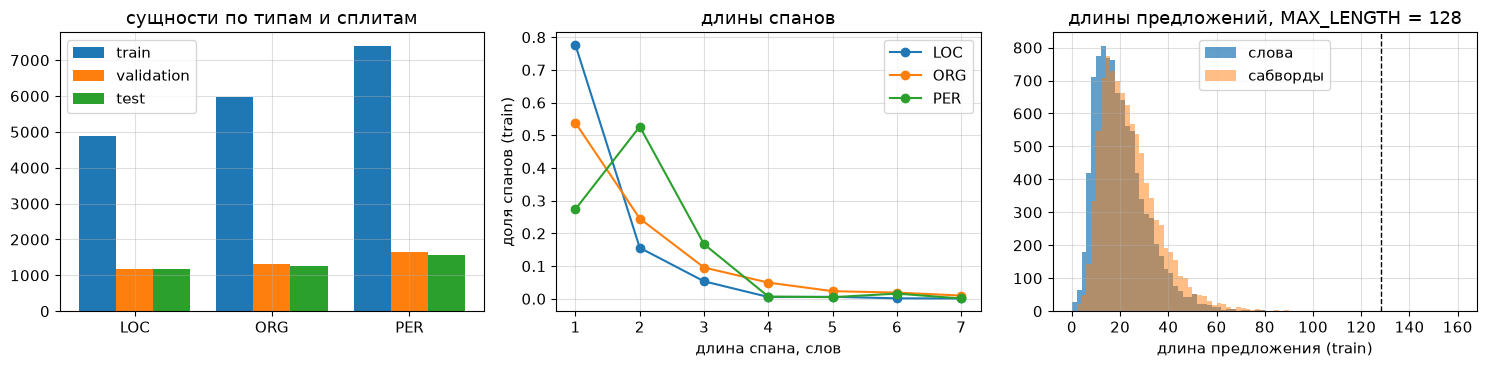

In [15]:
# ваша статистика: сущности по типам и сплитам, длины спанов в словах, длины предложений
from seqeval.metrics.sequence_labeling import get_entities   # (тип, начало, конец включительно)

SPLITS = ['train', 'validation', 'test']
TYPES = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})
ent_count, span_lens, surface = {}, {}, {}
for split in SPLITS:
    ent_count[split], span_lens[split], surface[split] = collections.Counter(), collections.defaultdict(list), set()
    for words, tags in zip(raw[split]['tokens'], raw[split]['ner_tags']):
        for t, s, e in get_entities([LABEL_NAMES[i] for i in tags]):
            ent_count[split][t] += 1
            span_lens[split][t].append(e - s + 1)
            surface[split].add((' '.join(words[s:e + 1]), t))

sent_words = {split: np.array([len(ws) for ws in raw[split]['tokens']]) for split in SPLITS}
print(f'{"split":<11}{"предл.":>7}{"слов":>8}' + ''.join(f'{t:>7}' for t in TYPES) + f'{"всего":>7}{"без сущн.":>10}')
for split in SPLITS:
    n_empty = sum(not any(tags) for tags in raw[split]['ner_tags'])
    print(f'{split:<11}{len(raw[split]):>7}{sent_words[split].sum():>8}'
          + ''.join(f'{ent_count[split][t]:>7}' for t in TYPES)
          + f'{sum(ent_count[split].values()):>7}{n_empty / len(raw[split]):>10.1%}')
n_tags = collections.Counter(LABEL_NAMES[i] for tags in raw['train']['ner_tags'] for i in tags)
print('доля тегов в train:', {t: f'{n_tags[t] / sum(n_tags.values()):.1%}' for t in LABEL_NAMES})

print('\nдлина спана в словах (train): среднее, доли 1/2/3/4+, максимум')
for t in TYPES:
    lens = np.array(span_lens['train'][t])
    print(f'  {t}: {lens.mean():.2f}, ' + ' / '.join(f'{np.mean(lens == k) if k < 4 else np.mean(lens >= 4):.1%}'
                                              for k in [1, 2, 3, 4]) + f', max {lens.max()}')

sub_len = np.array([len(ids) for ids in tokenizer(list(raw['train']['tokens']), is_split_into_words=True)['input_ids']])
print('\nдлина предложения в словах: ' + ', '.join(
    f'{s} медиана {np.median(sent_words[s]):.0f}, p95 {np.percentile(sent_words[s], 95):.0f}, max {sent_words[s].max()}' for s in SPLITS))
print(f'train в сабвордах (со спецтокенами): медиана {np.median(sub_len):.0f}, p95 {np.percentile(sub_len, 95):.0f}, '
      f'max {sub_len.max()}, длиннее MAX_LENGTH={MAX_LENGTH}: {np.sum(sub_len > MAX_LENGTH)}, '
      f'сабвордов на слово {(sub_len - 2).sum() / sent_words["train"].sum():.2f}')
for split in ['validation', 'test']:
    seen = {t: np.mean([(s, t) in surface['train'] for s, tt in surface[split] if tt == t]) for t in TYPES}
    print(f'уникальные сущности {split}, встречавшиеся в train с тем же типом: '
          + ', '.join(f'{t} {v:.0%}' for t, v in seen.items()))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
width = 0.27
for k, split in enumerate(SPLITS):
    axes[0].bar(np.arange(len(TYPES)) + (k - 1) * width, [ent_count[split][t] for t in TYPES], width, label=split)
axes[0].set_xticks(range(len(TYPES)), TYPES)
axes[0].set_title('сущности по типам и сплитам')
axes[0].legend()
for t in TYPES:
    lens = np.array(span_lens['train'][t])
    axes[1].plot(range(1, 8), [np.mean(lens == k) for k in range(1, 8)], 'o-', label=t)
axes[1].set_xlabel('длина спана, слов')
axes[1].set_ylabel('доля спанов (train)')
axes[1].set_title('длины спанов')
axes[1].legend()
axes[2].hist(sent_words['train'], bins=np.arange(0, 101, 2), alpha=0.7, label='слова')
axes[2].hist(sub_len, bins=np.arange(0, 161, 2), alpha=0.5, label='сабворды')
axes[2].axvline(MAX_LENGTH, color='k', ls='--', lw=1)
axes[2].set_xlabel('длина предложения (train)')
axes[2].set_title(f'длины предложений, MAX_LENGTH = {MAX_LENGTH}')
axes[2].legend()
for ax in axes:
    ax.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

**Вопрос.** Откуда датасет, под какой лицензией и как его размечали (вручную, автоматически, полуавтоматически)? Какие типы сущностей, сколько их по сплитам, какие типы редкие? Какие особенности данных (длина спанов, длина предложений, шум разметки) могут повлиять на обучение?

**Ответ.** Collection3 (`RCC-MSU/collection3`, parquet-ревизия `2398327…`) — русские новости из коллекции Persons-1000 (1000 документов, где изначально были размечены только персоны); ORG и LOC доразмечены вручную в Brat по правилам, близким к MUC-7, а перевод в IOB2 и деление на сплиты сделала команда DeepPavlov. Лицензия в карточке — `other`, раздел Licensing Information пуст, так что конкретной лицензии авторы не указали; датасет есть в списке разрешённых в 2.1, использую его только для учебного эксперимента. Типов три: в train 7406 PER, 5960 ORG и 4881 LOC, в validation 1641/1308/1168, в test 1570/1256/1175 — по-настоящему редких типов нет, реже всего LOC (27% сущностей train), а 82.3% тегов — `O`. Длины спанов сильно различаются: LOC в 77.6% случаев из одного слова, PER чаще всего из двух (52.7%), а ORG самые длинные и разнообразные — 12.1% спанов из 4+ слов, максимум 18, поэтому именно у ORG стоит ждать ошибок границ. Предложения короткие (медиана 18 слов, p95 41), в сабвордах медиана 21 и p95 46, длиннее `MAX_LENGTH = 128` всего 7 предложений train, так что обрезка почти ни на что не влияет. Сущности повторяются: из уникальных сущностей validation в train с тем же типом встречались 56% LOC, 42% ORG и лишь 30% PER — это важно для словарного бейзлайна в 3.1. Шум разметки небольшой: 6 предложений с `I-X` без `B-X` (2.2) и инициалы с точкой внутри спана PER (`Д . Медведев`).

## 2.2 Формат разметки (2.5 балла)

Модель предсказывает тег для каждого **сабворда**, а разметка дана по **словам** (или спанами по символам). Нужны две конвертации и тесты к ним.

1. `bio_to_spans(tags)` - BIO-теги слов -> список спанов `(start, end, type)`, `end` не включается. `B-X` начинает спан, `I-X` продолжает спан того же типа, иначе начинает новый (так делает `seqeval` в режиме по умолчанию), `O` закрывает спан. Тип может содержать дефис (`B-art-film` -> `art-film`)
2. `spans_to_bio(spans, n_words)` - обратно: спаны -> BIO-теги длины `n_words`
3. `align_labels(word_labels, word_ids, b_to_i=None)` - метки слов -> метки сабвордов. `word_ids` - выход `tokenizer(...).word_ids(i)`: номер слова для каждого сабворда, `None` у спецтокенов. По умолчанию метка слова ставится на его первый сабворд, спецтокены и продолжения слова получают `-100` (cross-entropy их игнорирует). Если передан словарь `b_to_i` (id тега `B-X` -> id тега `I-X`), метку получают все сабворды слова, у продолжений `B-X` заменяется на `I-X` - это вариант для абляции 5.2

Если ваш датасет не в формате «слова + BIO» (спаны по символам, IO-теги, CoNLL-текст), сначала приведите его к контракту из 2.1 и проверьте конвертацию на примерах глазами. Если датасет уже в BIO, сделайте обратную конвертацию: BIO -> спаны в JSON (`data/<split>_spans.jsonl`), прочитайте файл обратно, сконвертируйте в BIO и проверьте, что получилось то же самое (если в исходнике есть `I-X` без `B-X`, дословно не совпадет: сравните спаны и посчитайте такие предложения).

In [16]:
def bio_to_spans(tags):
    # ['B-PER', 'I-PER', 'O', 'B-LOC'] -> [(0, 2, 'PER'), (3, 4, 'LOC')]
    spans, start, cur = [], None, None
    for i, tag in enumerate(list(tags) + ['O']):   # 'O' в конце закрывает последний спан
        prefix, _, etype = tag.partition('-')       # 'B-art-film' -> ('B', '-', 'art-film')
        if prefix == 'I' and etype == cur:
            continue                                # продолжение текущего спана
        if cur is not None:
            spans.append((start, i, cur))
            start, cur = None, None
        if prefix in ('B', 'I'):                    # B-X или I-X без B-X начинают новый спан
            start, cur = i, etype
    return spans


def spans_to_bio(spans, n_words):
    # [(0, 2, 'PER')], 3 -> ['B-PER', 'I-PER', 'O']
    tags = ['O'] * n_words
    for start, end, etype in spans:
        if not 0 <= start < end <= n_words or any(t != 'O' for t in tags[start:end]):
            raise ValueError(f'спан {(start, end, etype)} вне [0, {n_words}) или пересекается с другим')
        tags[start:end] = ['B-' + etype] + ['I-' + etype] * (end - start - 1)
    return tags


def align_labels(word_labels, word_ids, b_to_i=None):
    # word_labels: id тегов слов; word_ids: номер слова для каждого сабворда (None - спецтокен) -> метки сабвордов
    labels, prev = [], None
    for w in word_ids:
        if w is None:
            labels.append(-100)                    # [CLS], [SEP], паддинг
        elif w != prev:
            labels.append(word_labels[w])          # первый сабворд слова
        elif b_to_i is not None:
            labels.append(b_to_i.get(word_labels[w], word_labels[w]))   # продолжение: B-X -> I-X
        else:
            labels.append(-100)                    # продолжение слова не учится
        prev = w
    return labels

In [17]:
tags = ['B-PER', 'I-PER', 'O', 'B-LOC', 'B-LOC', 'I-LOC', 'O', 'B-ORG']
assert bio_to_spans(tags) == [(0, 2, 'PER'), (3, 4, 'LOC'), (4, 6, 'LOC'), (7, 8, 'ORG')]
assert spans_to_bio(bio_to_spans(tags), len(tags)) == tags
assert bio_to_spans(['O', 'I-PER', 'I-PER', 'O']) == [(1, 3, 'PER')]       # I- без B- начинает спан
assert bio_to_spans(['B-PER', 'I-LOC', 'I-LOC']) == [(0, 1, 'PER'), (1, 3, 'LOC')]
assert bio_to_spans(['B-art-film', 'I-art-film', 'O']) == [(0, 2, 'art-film')]
assert bio_to_spans([]) == [] and bio_to_spans(['O'] * 3) == [] and spans_to_bio([], 2) == ['O', 'O']

rng = random.Random(0)
for _ in range(2000):   # туда-обратно на случайных спанах
    n, pos, spans = rng.randint(0, 15), 0, []
    while True:
        start = pos + rng.randint(0, 3)
        end = start + rng.randint(1, 4)
        if end > n:
            break
        spans.append((start, end, rng.choice(['PER', 'LOC', 'ORG'])))
        pos = end
    assert bio_to_spans(spans_to_bio(spans, n)) == spans, spans

word_ids = [None, 0, 0, 1, 2, 2, 2, None]
assert align_labels([1, 0, 3], word_ids) == [-100, 1, -100, 0, 3, -100, -100, -100]
assert align_labels([1, 0, 3], word_ids, b_to_i={1: 2, 3: 4}) == [-100, 1, 2, 0, 3, 4, 4, -100]
assert align_labels([2, 6], [None, 0, 0, 1, None], b_to_i={1: 2, 5: 6}) == [-100, 2, 2, 6, -100]
assert align_labels([5, 6, 0], [None, 0, None]) == [-100, 5, -100]        # обрезка по MAX_LENGTH
print('ok')

ok


In [18]:
# если датасет не в формате «слова + BIO»: конвертация в контракт из 2.1
# если уже в BIO: экспорт в спаны JSON (data/<split>_spans.jsonl), чтение обратно, BIO, сравнение с исходным
DATA_DIR = Path('data')
DATA_DIR.mkdir(exist_ok=True)
invalid_bio = {}
for split in SPLITS:
    path = DATA_DIR / f'{split}_spans.jsonl'
    with path.open('w', encoding='utf-8') as f:
        for ex in raw[split]:
            spans = bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
            f.write(json.dumps(dict(id=ex['id'], tokens=ex['tokens'], spans=spans), ensure_ascii=False) + '\n')

    records = [json.loads(line) for line in path.read_text(encoding='utf-8').splitlines()]
    assert len(records) == len(raw[split])
    n_tags_equal = n_spans_equal = n_seqeval_equal = 0
    invalid_bio[split] = []
    for ex, rec in zip(raw[split], records):
        assert rec['id'] == ex['id'] and rec['tokens'] == ex['tokens']
        orig = [LABEL_NAMES[i] for i in ex['ner_tags']]
        spans = [tuple(s) for s in rec['spans']]
        back = spans_to_bio(spans, len(rec['tokens']))
        n_tags_equal += back == orig
        n_spans_equal += bio_to_spans(back) == bio_to_spans(orig) == spans
        n_seqeval_equal += [(s, e + 1, t) for t, s, e in get_entities(orig)] == spans   # сверка с seqeval
        if back != orig:
            invalid_bio[split].append((ex['id'], rec['tokens'], orig, back))
    print(f'{split:<11}{path} {path.stat().st_size / 2**20:.2f} MB: BIO совпал дословно {n_tags_equal}/{len(records)}, '
          f'спаны совпали {n_spans_equal}, совпали со спанами seqeval {n_seqeval_equal}, '
          f'предложений с I-X без B-X: {len(invalid_bio[split])}')

for split, items in invalid_bio.items():
    for ex_id, words, orig, back in items:
        diff = [i for i, (a, b) in enumerate(zip(orig, back)) if a != b]
        lo, hi = max(0, diff[0] - 3), diff[-1] + 3
        print(f'  {split} id={ex_id}: ' + ' '.join(f'{w}/{a}' + (f'->{b}' if a != b else '')
                                                for w, a, b in zip(words[lo:hi], orig[lo:hi], back[lo:hi])))


# контракт 2.1: raw - BIO, восстановленный из спанов (I-X без B-X становится B-X, для seqeval спаны те же)
def normalize_bio(ex):
    tags = spans_to_bio(bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']]), len(ex['tokens']))
    return {'ner_tags': [LABEL_NAMES.index(t) for t in tags]}


raw = DatasetDict({split: raw[split].map(normalize_bio) for split in SPLITS})
assert all(spans_to_bio(bio_to_spans(t), len(t)) == t
           for split in SPLITS for t in ([LABEL_NAMES[i] for i in tags] for tags in raw[split]['ner_tags']))
print('после нормализации все предложения - валидный BIO')

train      data/train_spans.jsonl 3.23 MB: BIO совпал дословно 9296/9301, спаны совпали 9301, совпали со спанами seqeval 9301, предложений с I-X без B-X: 5
validation data/validation_spans.jsonl 0.75 MB: BIO совпал дословно 2153/2153, спаны совпали 2153, совпали со спанами seqeval 2153, предложений с I-X без B-X: 0
test       data/test_spans.jsonl 0.69 MB: BIO совпал дословно 1921/1922, спаны совпали 1922, совпали со спанами seqeval 1922, предложений с I-X без B-X: 1
  train id=1751: Воробьева/B-PER и/O ./O о/I-PER->B-PER ./O главы/O
  train id=2524: Власть/I-ORG->B-ORG "/O Вероника/B-PER
  train id=3143: Ответственность/I-ORG->B-ORG ./I-ORG
  train id=3144: Процветание/I-ORG->B-ORG 09/I-ORG "/I-ORG
  train id=7335: Северный/I-ORG->B-ORG Кавказ/I-ORG "/O
  test id=1242: Первоуральск/I-ORG->B-ORG "/O Ольгу/B-PER


после нормализации все предложения - валидный BIO


In [19]:
assert isinstance(raw, DatasetDict) and isinstance(LABEL_NAMES, list), 'raw и LABEL_NAMES - из 2.1 (после конвертации в 2.2)'
assert {'train', 'validation', 'test'} <= set(raw), 'нужны сплиты train / validation / test'
assert {'tokens', 'ner_tags'} <= set(raw['train'].column_names)
assert 'O' in LABEL_NAMES and all(re.fullmatch(r'O|[BI]-.+', t) for t in LABEL_NAMES), LABEL_NAMES
label2id = {t: i for i, t in enumerate(LABEL_NAMES)}
id2label = dict(enumerate(LABEL_NAMES))
ENTITY_TYPES = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})
B_TO_I = {label2id[t]: label2id['I-' + t[2:]] for t in LABEL_NAMES if t.startswith('B-') and 'I-' + t[2:] in label2id}


def subset(ds, n):
    return ds if n is None else ds.shuffle(seed=SEED).select(range(min(n, len(ds))))


data = DatasetDict(train=subset(raw['train'], N_TRAIN), validation=subset(raw['validation'], N_EVAL),
                   test=subset(raw['test'], N_EVAL))


def tokenize_and_align(batch, tok=None, label_all_subwords=False):
    tok = tok or tokenizer
    enc = tok(batch['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    enc['labels'] = [align_labels(tags, enc.word_ids(i), B_TO_I if label_all_subwords else None)
                     for i, tags in enumerate(batch['ner_tags'])]
    return enc


tokenized = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names)
print(data)
print('ENTITY_TYPES', ENTITY_TYPES)

# проверка на реальных данных: метки первых сабвордов восстанавливают метки слов, спаны совпадают
n_truncated = n_lost_words = n_checked = 0
for ex in data['train']:
    enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    ids = enc.word_ids()
    labels = align_labels(ex['ner_tags'], ids)
    got = {w: l for w, l in zip(ids, labels) if l != -100}
    assert got == {w: ex['ner_tags'][w] for w in set(ids) - {None}}
    n_truncated += len(enc['input_ids']) == MAX_LENGTH
    n_lost = len(ex['tokens']) - len(got)
    n_lost_words += n_lost
    if n_lost == 0:
        back = [LABEL_NAMES[got[w]] for w in range(len(ex['tokens']))]
        assert bio_to_spans(back) == bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
        n_checked += 1
print(f'train: проверено {n_checked} предложений, обрезано по MAX_LENGTH {n_truncated}, слов без сабвордов или за обрезкой {n_lost_words}')

ex = data['train'][0]
enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
for sub, w, l in zip(enc.tokens(), enc.word_ids(), align_labels(ex['ner_tags'], enc.word_ids())):
    print(f'{sub:<16}{str(w):>5}  {LABEL_NAMES[l] if l != -100 else -100}')

Map:   0%|          | 0/9301 [00:00<?, ? examples/s]

Map:  54%|█████▍    | 5000/9301 [00:00<00:00, 40776.03 examples/s]

Map: 100%|██████████| 9301/9301 [00:00<00:00, 42424.44 examples/s]

Map:   0%|          | 0/2153 [00:00<?, ? examples/s]

Map: 100%|██████████| 2153/2153 [00:00<00:00, 42972.34 examples/s]

Map:   0%|          | 0/1922 [00:00<?, ? examples/s]

Map: 100%|██████████| 1922/1922 [00:00<00:00, 42168.58 examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 9301
    })
    validation: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 2153
    })
    test: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 1922
    })
})
ENTITY_TYPES ['LOC', 'ORG', 'PER']


train: проверено 9291 предложений, обрезано по MAX_LENGTH 7, слов без сабвордов или за обрезкой 369
[CLS]            None  -100
Дополнение          0  O
:                   1  O
Д                   2  B-PER
.                   3  I-PER
Медведев            4  I-PER
присвоил            5  O
звания              6  O
сотрудников         7  O
полиции             8  O
и                   9  O
перена             10  O
##знач             10  -100
##ил               10  -100
14                 11  O
руководителей      12  O
УВД                13  B-ORG
,                  14  O
ГУВД               15  B-ORG
и                  16  O
МВД                17  B-ORG
по                 18  O
субъекта           19  O
##м                19  -100
РФ                 20  B-LOC
.                  21  O
[SEP]            None  -100


**Вопрос.** Почему метка ставится только на первый сабворд, а остальным -100, и что -100 делает в loss? Сколько предложений обрезано по `MAX_LENGTH` и сколько слов не получили ни одного сабворда - как это повлияет на метрику? Какие проблемы нашлись при конвертации вашего датасета (невалидный BIO, пересекающиеся или вложенные спаны, расхождение токенизации)?

**Ответ.** У слова один тег, а у продолжений сабвордов «правильной» метки нет (пришлось бы договариваться о `B-X` → `I-X`), к тому же метки на всех сабвордах давали бы длинным словам больший вес в loss. Значение -100 — `ignore_index` у `CrossEntropyLoss`: такие позиции не входят ни в сумму, ни в знаменатель среднего и не дают градиента. На полном train обрезано по `MAX_LENGTH` 7 предложений из 9301, и 369 слов не получили сабвордов или ушли за обрезку — почти все это хвосты тех же 7 предложений (самое длинное — 292 сабворда), а без сабвордов остаются лишь единичные невидимые символы вроде мягкого переноса. В `predict_word_tags` такие слова получают `O`, поэтому сущности в хвостах засчитываются как пропуски и чуть снижают recall, но это ~0.2% слов (369 из 187 656). Датасет уже в BIO, поэтому я выгрузил спаны в `data/<split>_spans.jsonl`, прочитал обратно и собрал BIO: дословно совпали 9296/9301 предложений train, 2153/2153 validation и 1921/1922 test, а спаны совпали во всех 13 376 предложениях и со спанами `seqeval`. Расхождения — 6 предложений с `I-X` без `B-X` (например, `Власть/I-ORG` или `Северный/I-ORG Кавказ/I-ORG` в начале предложения — похоже, название в кавычках разрезано границей предложения, а `о/I-PER` после `Воробьева и .` — просто ошибка); я привёл их к `B-X`, для `seqeval` спаны от этого не меняются. Вложенных и пересекающихся спанов в BIO не бывает, а расхождений токенизации, кроме мягкого переноса, не нашлось.

---
# 3. Бейзлайн

## 3.1 Бейзлайн до дообучения (2 балла)

Метрики считаются по словам: тег слова - предсказание на его первом сабворде (функция `predict_word_tags` ниже). F1 по сущностям - `seqeval`: спан засчитывается, только если совпали обе границы и тип.

1. Реализуйте словарный бейзлайн: `fit_majority_tagger` запоминает для каждого слова из train самый частый его тег, `predict_majority` размечает предложение, незнакомые слова получают `O`
2. Посчитайте метрики бейзлайна и энкодера со случайно инициализированной головой (без дообучения) на validation

In [20]:
@torch.no_grad()
def predict_word_tags(model, tokens_list, tok=None, batch_size=64, return_probs=False, dev=None):
    # теги слов по первому сабворду; слова без сабвордов или за MAX_LENGTH получают 'O' (вероятность 1)
    tok, dev = tok or tokenizer, dev or device
    tokens_list = [list(ws) for ws in tokens_list]
    model.eval().to(dev)
    all_tags, all_probs = [], []
    for start in range(0, len(tokens_list), batch_size):
        batch = tokens_list[start:start + batch_size]
        enc = tok(batch, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors='pt')
        probs = model(**{k: v.to(dev) for k, v in enc.items()}).logits.float().softmax(-1).cpu()
        conf, best = probs.max(-1)
        for i, words in enumerate(batch):
            tags, word_conf, seen = ['O'] * len(words), [1.0] * len(words), set()
            for pos, w in enumerate(enc.word_ids(i)):
                if w is None or w in seen:
                    continue
                seen.add(w)
                tags[w], word_conf[w] = model.config.id2label[int(best[i, pos])], float(conf[i, pos])
            all_tags.append(tags)
            all_probs.append(word_conf)
    return (all_tags, all_probs) if return_probs else all_tags


def entity_scores(gold, pred):
    return dict(f1_micro=f1_score(gold, pred, average='micro', zero_division=0),
                f1_macro=f1_score(gold, pred, average='macro', zero_division=0),
                precision=precision_score(gold, pred, zero_division=0),
                recall=recall_score(gold, pred, zero_division=0))


def make_model(model_id=None, revision=None):
    return AutoModelForTokenClassification.from_pretrained(
        model_id or MODEL_ID, revision=revision or REVISION,
        num_labels=len(LABEL_NAMES), id2label=id2label, label2id=label2id)


val_tokens = [list(ws) for ws in data['validation']['tokens']]
val_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['validation']['ner_tags']]

In [21]:
def fit_majority_tagger(tokens_list, tags_list):
    # -> dict: слово -> самый частый тег этого слова в train
    counts = collections.defaultdict(collections.Counter)
    for words, tags in zip(tokens_list, tags_list):
        for word, tag in zip(words, tags):
            counts[word][tag] += 1
    return {word: c.most_common(1)[0][0] for word, c in counts.items()}


def predict_majority(tagger, words):
    # -> список тегов той же длины; незнакомое слово -> 'O'
    return [tagger.get(word, 'O') for word in words]

In [22]:
toy_tokens = [['Анна', 'живет', 'в', 'Москве'], ['Москве', 'не', 'до', 'сна'], ['Анна', 'Каренина'], ['в', 'Москве']]
toy_tags = [['B-PER', 'O', 'O', 'B-LOC'], ['B-LOC', 'O', 'O', 'O'], ['B-PER', 'I-PER'], ['O', 'B-ORG']]
toy = fit_majority_tagger(toy_tokens, toy_tags)
assert toy['Москве'] == 'B-LOC' and toy['Анна'] == 'B-PER' and toy['Каренина'] == 'I-PER'
assert fit_majority_tagger([['Ленина']] * 4, [['B-LOC'], ['B-PER'], ['B-PER'], ['B-ORG']])['Ленина'] == 'B-PER'   # самый частый тег, а не первый или последний
assert predict_majority(toy, ['Анна', 'из', 'Москве']) == ['B-PER', 'O', 'B-LOC']
assert predict_majority(toy, []) == []

baseline = {}   # ваш код: baseline['majority'] и baseline['random_head'] - словари entity_scores
import gc


def free_memory():
    gc.collect()
    if device.type == 'mps':
        torch.mps.empty_cache()
    elif device.type == 'cuda':
        torch.cuda.empty_cache()


del demo_model   # демо-модель из 1.2 больше не нужна
train_tokens = [list(ws) for ws in data['train']['tokens']]
train_tags = [[LABEL_NAMES[i] for i in tags] for tags in data['train']['ner_tags']]
majority = fit_majority_tagger(train_tokens, train_tags)
majority_pred = [predict_majority(majority, ws) for ws in val_tokens]
baseline['majority'] = entity_scores(val_gold, majority_pred)

set_seed(SEED)
random_model = make_model()   # энкодер предобучен, голова Linear(768, 7) инициализирована случайно
random_pred = predict_word_tags(random_model, val_tokens)
baseline['random_head'] = entity_scores(val_gold, random_pred)
del random_model
free_memory()

print(f'{"":<13}' + ''.join(f'{k:>11}' for k in baseline['majority']))
for name, scores in baseline.items():
    print(f'{name:<13}' + ''.join(f'{v:>11.4f}' for v in scores.values()))
val_words = [w for ws in val_tokens for w in ws]
val_ent_words = [w for ws, ts in zip(val_tokens, val_gold) for w, t in zip(ws, ts) if t != 'O']
print(f'\nсловарь: {len(majority)} слов; незнакомых слов в validation {np.mean([w not in majority for w in val_words]):.1%}, '
      f'среди слов сущностей {np.mean([w not in majority for w in val_ent_words]):.1%}')
maj_report = classification_report(val_gold, majority_pred, output_dict=True, zero_division=0)
print('majority по типам (P / R / F1):', {t: tuple(round(float(maj_report[t][k]), 3) for k in ['precision', 'recall', 'f1-score'])
                                         for t in ENTITY_TYPES})
n_val = sum(map(len, val_gold))
for name, pred in [('majority', majority_pred), ('random_head', random_pred)]:
    tags = collections.Counter(t for ts in pred for t in ts)
    print(f'{name}: доли предсказанных тегов', {t: f'{tags[t] / n_val:.1%}' for t in LABEL_NAMES},
          f'| спанов предсказано {sum(len(bio_to_spans(ts)) for ts in pred)}, в gold {sum(len(bio_to_spans(ts)) for ts in val_gold)}')

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 57488.20it/s]

                f1_micro   f1_macro  precision     recall
majority          0.5615     0.5787     0.5629     0.5601
random_head       0.0250     0.0224     0.0143     0.0984

словарь: 27410 слов; незнакомых слов в validation 11.2%, среди слов сущностей 20.4%
majority по типам (P / R / F1): {'LOC': (0.753, 0.763, 0.758), 'ORG': (0.55, 0.576, 0.563), 'PER': (0.428, 0.403, 0.415)}
majority: доли предсказанных тегов {'O': '88.9%', 'B-PER': '2.5%', 'I-PER': '1.8%', 'B-ORG': '2.5%', 'I-ORG': '1.2%', 'B-LOC': '2.4%', 'I-LOC': '0.7%'} | спанов предсказано 4097, в gold 4117
random_head: доли предсказанных тегов {'O': '18.1%', 'B-PER': '11.2%', 'I-PER': '25.5%', 'B-ORG': '7.8%', 'I-ORG': '4.8%', 'B-LOC': '22.0%', 'I-LOC': '10.6%'} | спанов предсказано 28301, в gold 4117


**Вопрос.** Какой F1 у словарного бейзлайна и почему он такой (вспомните, как размечен ваш датасет и как часто сущности повторяются)? Что предсказывает энкодер со случайной головой и почему его F1 близок к нулю, хотя энкодер предобучен?

**Ответ.** Словарный бейзлайн на validation даёт F1 micro 0.5615 (macro 0.5787, P 0.563, R 0.560): новости много раз упоминают одни и те же места и организации (56% уникальных LOC и 42% ORG validation есть в train), поэтому у LOC F1 0.758 и у ORG 0.563. У PER всего 0.415: люди чаще новые (в train встречались 30%), а словарь не видит контекста — фамилия бывает и `B-PER`, и `I-PER` после имени, и спан рвётся на границе. Незнакомые слова (11.2% слов validation и 20.4% слов внутри сущностей) получают `O`, что режет recall. Энкодер со случайной головой даёт F1 0.025: признаки энкодера осмысленные, но случайная `Linear(768, 7)` ничего не знает о наших id тегов, и предсказания размазаны по всем тегам — `O` только у 18.1% слов вместо 82% в разметке, 28 301 предсказанный спан против 4117 истинных. Отсюда precision 0.014 и recall 0.098 на случайных совпадениях: связь признаков с тегами должна выучить голова, а заодно и подстроиться энкодер.

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Реализуйте `train_ner`: дообучение модели на `tokenized['train']` с оценкой loss на `tokenized['validation']` по ходу обучения (не реже ~10 раз за обучение, чтобы получились кривые). Можно `Trainer` + `DataCollatorForTokenClassification` (он дополняет `labels` значением -100) или свой цикл. Параметр `freeze_encoder=True` замораживает все, кроме головы - он нужен для абляции 5.2. Функция возвращает `(history, seconds)`: `history` - список словарей с ключами `step` и `loss` (train) или `eval_loss`, как `trainer.state.log_history`.

Гиперпараметры выберите и обоснуйте: learning rate (у base-моделей обычно 2e-5 - 5e-5, маленьким моделям нужен больше), batch size, число эпох, warmup, weight decay, `fp16` на GPU.

В transformers 5 аргументы называются `eval_strategy` (не `evaluation_strategy`) и `processing_class` (не `tokenizer`), туториалы под версию 4 с ними падают. Чекпойнты не нужны: `save_strategy='no'`.

In [23]:
LR = 3e-5          # середина диапазона 2e-5 - 5e-5 для BERT-base
BATCH_SIZE = 32    # эффективный батч (на шаг оптимизатора)
# MPS на Mac 16 ГБ: каждая новая длина батча навсегда добавляет ~0.4 ГБ памяти Metal, а батч 32 x 128 - ~8 ГБ.
# Поэтому на MPS - одна форма 8 x MAX_LENGTH и накопление градиента по 4 микробатчам; на GPU - батч целиком
MICRO_BATCH = 8 if device.type == 'mps' else BATCH_SIZE
WARMUP = 0.1       # доля шагов на линейный разогрев LR, дальше линейное затухание до 0
WEIGHT_DECAY = 0.01
N_EVALS = 15       # сколько раз за обучение считать train и validation loss


def train_ner(model, train_ds, eval_ds, epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, freeze_encoder=False,
              tok=None, out_dir='runs/main'):
    # -> (history, seconds); history - список dict со 'step' и 'loss' или 'eval_loss'
    tok = tok or tokenizer
    if freeze_encoder:   # учится только голова (classifier); у dropout параметров нет
        for p in getattr(model, model.base_model_prefix).parameters():
            p.requires_grad = False
    total_steps = math.ceil(len(train_ds) / batch_size) * epochs
    every = max(1, total_steps // N_EVALS)
    args = TrainingArguments(
        output_dir=out_dir, num_train_epochs=epochs, learning_rate=lr,
        per_device_train_batch_size=min(MICRO_BATCH, batch_size), per_device_eval_batch_size=min(MICRO_BATCH, batch_size),
        gradient_accumulation_steps=max(1, batch_size // MICRO_BATCH), prediction_loss_only=True,
        warmup_steps=WARMUP, weight_decay=WEIGHT_DECAY, lr_scheduler_type='linear',
        eval_strategy='steps', eval_steps=every, logging_strategy='steps', logging_steps=every,
        save_strategy='no', report_to='none', fp16=torch.cuda.is_available(),
        seed=SEED, data_seed=SEED, disable_tqdm=True)
    trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=eval_ds,
                      data_collator=DataCollatorForTokenClassification(tok, padding='max_length', max_length=MAX_LENGTH), processing_class=tok)
    trainer.remove_callback(transformers.trainer_callback.PrinterCallback)   # лог печатаем сами после обучения
    # BertForTokenClassification считает средний CE по микробатчу и не использует num_items_in_batch, а Trainer видит
    # **kwargs в forward и считает лосс уже нормированным: без этой строки лосс и градиент при накоплении были бы x4
    trainer.loss_is_scaled_for_ga = False
    start = time.perf_counter()
    trainer.train()
    seconds = time.perf_counter() - start
    return trainer.state.log_history, seconds

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 47978.04it/s]

/Users/paveltischenko/dl_2026_j3310_ai/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


обучение: 1277.5 c на mps, 9301 предложений, 3 эпох(а)


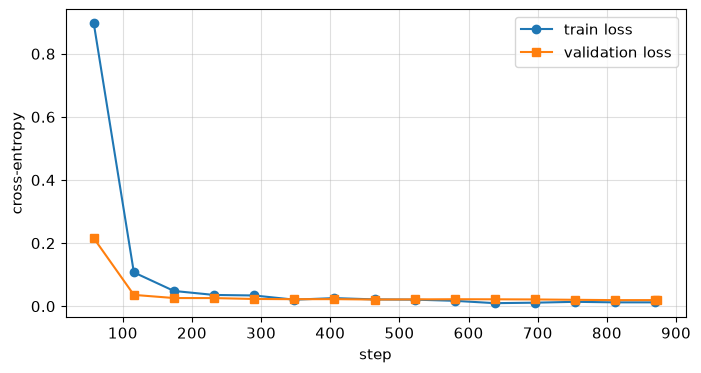

In [24]:
set_seed(SEED)
model = make_model()
history, train_seconds = train_ner(model, tokenized['train'], tokenized['validation'])
RUN_TIMES['train_main_sec'] = train_seconds
train_curve = [(h['step'], h['loss']) for h in history if 'loss' in h]
eval_curve = [(h['step'], h['eval_loss']) for h in history if 'eval_loss' in h]
assert len(train_curve) >= 2 and len(eval_curve) >= 2, 'логируйте train и eval loss по ходу обучения'
print(f'обучение: {train_seconds:.1f} c на {DEVICE_NAME}, {len(tokenized["train"])} предложений, {EPOCHS} эпох(а)')

plt.figure(figsize=(8, 4))
plt.plot(*zip(*train_curve), 'o-', label='train loss')
plt.plot(*zip(*eval_curve), 's-', label='validation loss')
plt.xlabel('step')
plt.ylabel('cross-entropy')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

In [25]:
# лог обучения: train loss - среднее за последний интервал логирования, eval loss - на validation
steps_per_epoch = math.ceil(len(tokenized['train']) / BATCH_SIZE)
eval_by_step = dict(eval_curve)
print(f'{steps_per_epoch} шагов на эпоху, LR {LR}, batch {BATCH_SIZE} = {MICRO_BATCH} x {BATCH_SIZE // MICRO_BATCH}, warmup {WARMUP:.0%}, '
      f'weight decay {WEIGHT_DECAY}, fp16 {torch.cuda.is_available()}')
print('step  epoch  train   eval')
for step, loss in train_curve:
    print(f'{step:>4}  {step / steps_per_epoch:5.2f}  {loss:.4f}  {eval_by_step.get(step, float("nan")):.4f}')
best_step, best_loss = min(eval_curve, key=lambda x: x[1])
print(f'минимум eval loss {best_loss:.4f} на шаге {best_step} (эпоха {best_step / steps_per_epoch:.2f})')

291 шагов на эпоху, LR 3e-05, batch 32 = 8 x 4, warmup 10%, weight decay 0.01, fp16 False
step  epoch  train   eval
  58   0.20  0.8970  0.2158
 116   0.40  0.1073  0.0359
 174   0.60  0.0484  0.0259
 232   0.80  0.0357  0.0258
 290   1.00  0.0340  0.0230
 348   1.20  0.0208  0.0223
 406   1.40  0.0257  0.0224
 464   1.59  0.0216  0.0212
 522   1.79  0.0209  0.0216
 580   1.99  0.0171  0.0221
 638   2.19  0.0097  0.0219
 696   2.39  0.0112  0.0214
 754   2.59  0.0139  0.0203
 812   2.79  0.0123  0.0193
 870   2.99  0.0123  0.0194
минимум eval loss 0.0193 на шаге 812 (эпоха 2.79)


**Вопрос.** Почему выбраны такие гиперпараметры? Что видно на кривых: есть ли переобучение, нужно ли больше эпох? Сколько заняло обучение и на каком устройстве?

**Ответ.** LR 3e-5 — середина диапазона 2e-5 – 5e-5, рекомендованного для дообучения BERT-base; эффективный батч 32, 3 эпохи (873 шага), warmup 10% с линейным затуханием (пока голова случайная, большие градиенты на старте могут испортить предобученные веса) и weight decay 0.01. Устройство — Apple M5 (MPS) с 16 ГБ общей памяти: батч 32 × 128 требовал ~8 ГБ, а каждая новая длина батча навсегда добавляла ~0.4 ГБ памяти Metal, поэтому на MPS батч собирается из 4 микробатчей одной формы 8 × 128 с накоплением градиента, а процессу выставлен лимит памяти (на GPU `MICRO_BATCH` равен всему батчу, `fp16` включается только на CUDA). Ещё одна деталь: `BertForTokenClassification` усредняет CE по микробатчу, а Trainer считал лосс уже нормированным на накопление, и без `trainer.loss_is_scaled_for_ga = False` лосс в логе и градиент были бы в 4 раза больше. По кривым eval loss падает с 0.216 (шаг 58) до 0.023 к концу первой эпохи и дальше почти стоит на 0.019–0.022, минимум 0.0193 на шаге 812 (эпоха 2.79), а train loss опускается до 0.010–0.014. Переобучения нет — eval loss не растёт, хотя разрыв с train виден; больше эпох почти ничего не дадут: за эпохи 2–3 eval loss улучшился лишь на ~0.004. Обучение заняло 1277.5 с (21 мин) на MPS вместе с 15 оценками на validation; паддинг до 128 при медиане 21 сабворд — главная плата за ограничение памяти.

## 4.2 Метрики (3 балла)

1. Посчитайте на validation и test отчет `seqeval` по типам (P/R/F1, support), micro и macro F1
2. Реализуйте `token_f1(gold, pred)` - micro-F1 по словам: верное срабатывание - слово, у которого предсказанный тег не `O` и совпадает с истинным; тег `O` в precision и recall не участвует; если не-`O` слов нет ни в gold, ни в pred, функция возвращает 0.0
3. Сравните токенный F1 и F1 по сущностям и объясните разницу

In [26]:
def token_f1(gold, pred):
    # gold, pred: списки списков BIO-тегов -> micro-F1 по словам без тега O
    tp = n_gold = n_pred = 0
    for gs, ps in zip(gold, pred, strict=True):
        for g, p in zip(gs, ps, strict=True):
            n_gold += g != 'O'
            n_pred += p != 'O'
            tp += p != 'O' and p == g
    if tp == 0:
        return 0.0
    precision, recall = tp / n_pred, tp / n_gold
    return 2 * precision * recall / (precision + recall)

In [27]:
g, p = [['B-PER', 'I-PER', 'O', 'B-LOC']], [['B-PER', 'O', 'O', 'B-LOC']]
assert abs(token_f1(g, p) - 0.8) < 1e-9                       # 2 верных слова из 2 предсказанных и 3 истинных
assert abs(f1_score(g, p) - 0.5) < 1e-9                       # а по сущностям верна одна из двух
assert token_f1([['O', 'O']], [['O', 'O']]) == 0.0 and token_f1(g, g) == 1.0

final = {}       # ваш код: метрики на test: f1_micro, f1_macro, precision, recall, token_f1, per_type
val_pred = []    # предсказанные теги validation (список списков), нужны в 5.1
test_tokens = [list(ws) for ws in data['test']['tokens']]
test_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['test']['ner_tags']]
start = time.perf_counter()
val_pred = predict_word_tags(model, val_tokens)
test_pred = predict_word_tags(model, test_tokens)
RUN_TIMES['predict_val_test_sec'] = time.perf_counter() - start


def full_scores(gold, pred):
    report = classification_report(gold, pred, output_dict=True, zero_division=0)
    per_type = {t: {k: report[t][k] for k in ['precision', 'recall', 'f1-score', 'support']} for t in ENTITY_TYPES}
    return dict(**entity_scores(gold, pred), token_f1=token_f1(gold, pred), per_type=per_type)


final_val = full_scores(val_gold, val_pred)
final = full_scores(test_gold, test_pred)
for name, gold, pred, scores in [('validation', val_gold, val_pred, final_val), ('test', test_gold, test_pred, final)]:
    print(f'=== {name}: {len(gold)} предложений')
    print(classification_report(gold, pred, digits=4, zero_division=0))
    print('  '.join(f'{k} {scores[k]:.4f}' for k in ['f1_micro', 'f1_macro', 'precision', 'recall', 'token_f1']))
print(f'предсказание validation + test: {RUN_TIMES["predict_val_test_sec"]:.1f} c')

=== validation: 2153 предложений


              precision    recall  f1-score   support

         LOC     0.9797    0.9897    0.9847      1168
         ORG     0.9283    0.9495    0.9388      1308
         PER     0.9963    0.9970    0.9966      1641

   micro avg     0.9697    0.9798    0.9747      4117
   macro avg     0.9681    0.9787    0.9734      4117
weighted avg     0.9700    0.9798    0.9749      4117

f1_micro 0.9747  f1_macro 0.9734  precision 0.9697  recall 0.9798  token_f1 0.9813
=== test: 1922 предложений
              precision    recall  f1-score   support

         LOC     0.9723    0.9872    0.9797      1175
         ORG     0.9251    0.9443    0.9346      1256
         PER     0.9956    0.9981    0.9968      1570

   micro avg     0.9664    0.9780    0.9722      4001
   macro avg     0.9643    0.9765    0.9704      4001
weighted avg     0.9666    0.9780    0.9723      4001

f1_micro 0.9722  f1_macro 0.9704  precision 0.9664  recall 0.9780  token_f1 0.9802
предсказание validation + test: 22.7 c


In [28]:
# recall по сущностям test в разрезе типа: встречалась ли строка сущности в train с тем же типом и длина спана
train_surface = {(' '.join(ws[s:e]), t) for ws, ts in zip(train_tokens, train_tags) for s, e, t in bio_to_spans(ts)}
hit = collections.defaultdict(lambda: [0, 0])
for ws, gs, ps in zip(test_tokens, test_gold, test_pred):
    pred_spans = set(bio_to_spans(ps))
    for s, e, t in bio_to_spans(gs):
        seen = 'seen' if (' '.join(ws[s:e]), t) in train_surface else 'unseen'
        for key in [(t, seen), (t, f'len {min(e - s, 3)}{"+" if e - s >= 3 else ""}')]:
            hit[key][0] += (s, e, t) in pred_spans
            hit[key][1] += 1
cols = ['seen', 'unseen', 'len 1', 'len 2', 'len 3+']
print('recall на test (в скобках - число спанов)')
print(f'{"":<6}' + ''.join(f'{c:>15}' for c in cols))
for t in ENTITY_TYPES:
    print(f'{t:<6}' + ''.join(f'{hit[(t, c)][0] / max(1, hit[(t, c)][1]):>8.3f} ({hit[(t, c)][1]:>4})' for c in cols))

recall на test (в скобках - число спанов)
                 seen         unseen          len 1          len 2         len 3+
LOC      0.997 ( 892)   0.958 ( 283)   0.995 ( 936)   0.989 ( 181)   0.862 (  58)
ORG      0.980 ( 807)   0.880 ( 449)   0.973 ( 678)   0.945 ( 309)   0.870 ( 269)
PER      1.000 ( 621)   0.997 ( 949)   0.997 ( 337)   0.998 ( 816)   1.000 ( 417)


**Вопрос.** Какой тип сущностей распознается хуже всего и почему (частота, длина спанов, разнообразие)? Чем отличаются micro и macro F1 в вашем случае? Чем отличаются токенный F1 и F1 по сущностям в ваших числах и за счет чего (какой выше и почему)? Какой из них ближе к тому, что нужно пользователю NER?

**Ответ.** Хуже всего ORG: на test F1 0.9346 (P 0.925, R 0.944) против 0.9797 у LOC и 0.9968 у PER. Это самые длинные и разнообразные спаны (12.1% из 4+ слов), а граница зависит от договорённостей разметки (`ГУ МВД` или `МВД`): recall ORG на спанах из 3+ слов — 0.870, на организациях, не встречавшихся в train, — 0.880 против 0.980 на знакомых. PER почти решён даже для новых людей (recall 0.997 на незнакомых): у имён сильные признаки — заглавная буква и характерные окончания. Micro и macro F1 почти совпадают (0.9722 и 0.9704), потому что типы сбалансированы (1175/1256/1570 спанов); macro чуть ниже, так как в нём слабый ORG весит ровно треть. Токенный F1 выше сущностного: 0.9802 против 0.9722 на test (0.9813 против 0.9747 на validation), потому что ошибка границы в спане из трёх слов оставляет два верных слова, а по сущностям весь спан считается и ложным срабатыванием, и пропуском. Пользователю NER ближе F1 по сущностям: ему нужно извлечь имя или организацию целиком, а не большую часть слов.

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

Аналог разбора ошибок детектора по IoU. Реализуйте `categorize_errors(gold_spans, pred_spans)`: каждый истинный спан получает ровно одну категорию, предсказанный спан, не пересекающийся ни с одним истинным, - категорию `spurious`. Возвращается список `(категория, истинный спан или None, предсказанный спан или None)`:

- `correct` - есть предсказанный спан с теми же границами и типом
- `boundary` - точного совпадения нет, но есть пересекающийся предсказанный спан того же типа (ошибка границы, аналог ошибки локализации)
- `type` - пересекающегося спана того же типа нет, но есть пересекающийся спан другого типа (ошибка типа, аналог ошибки класса)
- `missed` - ни один предсказанный спан не пересекается с истинным (пропуск)
- `spurious` - лишний спан (ложное срабатывание)

Посчитайте категории на validation, доли среди ошибок, покажите 5+ примеров ошибок разных категорий глазами (предложение, истинный и предсказанный спаны).

In [29]:
ERROR_CATEGORIES = ['correct', 'boundary', 'type', 'missed', 'spurious']


def categorize_errors(gold_spans, pred_spans):
    # -> [(категория, gold-спан или None, pred-спан или None), ...]
    def overlap(a, b):   # длина пересечения полуинтервалов [start, end)
        return max(0, min(a[1], b[1]) - max(a[0], b[0]))

    pred_set, result = set(pred_spans), []
    for g in gold_spans:
        if g in pred_set:
            result.append(('correct', g, g))
            continue
        crossing = sorted((p for p in pred_spans if overlap(g, p) > 0), key=lambda p: -overlap(g, p))
        same_type = [p for p in crossing if p[2] == g[2]]
        if same_type:
            result.append(('boundary', g, same_type[0]))
        elif crossing:
            result.append(('type', g, crossing[0]))
        else:
            result.append(('missed', g, None))
    for p in pred_spans:
        if not any(overlap(g, p) > 0 for g in gold_spans):
            result.append(('spurious', None, p))
    return result

In [30]:
gold = [(0, 2, 'PER'), (4, 5, 'LOC'), (7, 9, 'ORG'), (11, 12, 'PER')]
pred = [(0, 2, 'PER'), (4, 6, 'LOC'), (7, 9, 'LOC'), (13, 14, 'ORG')]
res = categorize_errors(gold, pred)
assert collections.Counter(c for c, _, _ in res) == {'correct': 1, 'boundary': 1, 'type': 1, 'missed': 1, 'spurious': 1}
assert ('type', (7, 9, 'ORG'), (7, 9, 'LOC')) in res and ('spurious', None, (13, 14, 'ORG')) in res
assert ('boundary', (4, 5, 'LOC'), (4, 6, 'LOC')) in res and ('missed', (11, 12, 'PER'), None) in res
assert categorize_errors([], []) == [] and categorize_errors([], [(0, 1, 'PER')]) == [('spurious', None, (0, 1, 'PER'))]
assert [c for c, _, _ in categorize_errors([(0, 3, 'LOC')], [(1, 2, 'PER'), (2, 3, 'LOC')])] == ['boundary']
assert [c for c, _, _ in categorize_errors([(0, 2, 'LOC'), (2, 4, 'LOC')], [(0, 4, 'LOC')])] == ['boundary', 'boundary']
assert sorted(c for c, _, _ in categorize_errors([(0, 2, 'PER')], [(2, 3, 'PER')])) == ['missed', 'spurious']   # end не включается: спаны только соприкасаются

errors = {}   # ваш код: {категория: число} на validation, затем доли и 5+ примеров
val_errors = [(i, *r) for i, (gs, ps) in enumerate(zip(val_gold, val_pred))
              for r in categorize_errors(bio_to_spans(gs), bio_to_spans(ps))]
counts = collections.Counter(c for _, c, _, _ in val_errors)
errors = {c: counts[c] for c in ERROR_CATEGORIES}
n_err = sum(v for c, v in errors.items() if c != 'correct')
print(f'validation: {len(val_gold)} предложений, истинных спанов {sum(v for c, v in errors.items() if c != "spurious")}, ошибок {n_err}')
for c in ERROR_CATEGORIES:
    by_type = collections.Counter((g or p)[2] for _, cc, g, p in val_errors if cc == c)
    share = '' if c == 'correct' else f'{errors[c] / max(1, n_err):.1%} ошибок'
    print(f'  {c:<9}{errors[c]:>6}  {share:<13} по типам: {dict(sorted(by_type.items()))}')
print('  (по типам: истинный тип, у spurious - предсказанный)')
type_pairs = collections.Counter(f'{g[2]}->{p[2]}' for _, c, g, p in val_errors if c == 'type')
print('ошибки типа (истинный -> предсказанный):', dict(type_pairs.most_common()))
boundary_kind = collections.Counter(('длиннее' if p[1] - p[0] > g[1] - g[0] else 'короче' if p[1] - p[0] < g[1] - g[0] else 'сдвиг')
                                    for _, c, g, p in val_errors if c == 'boundary')
print('ошибки границы: предсказанный спан относительно истинного', dict(boundary_kind))


def show(i, g, p, window=6):
    words = val_tokens[i]
    lo = max(0, min(x[0] for x in (g, p) if x) - window)
    hi = min(len(words), max(x[1] for x in (g, p) if x) + window)
    span_text = lambda x: f'[{" ".join(words[x[0]:x[1]])}]/{x[2]}' if x else '-'
    return (f'{"..." if lo else ""}{" ".join(words[lo:hi])}{"..." if hi < len(words) else ""}\n'
            f'        gold {span_text(g)}   pred {span_text(p)}')


rng = random.Random(SEED)
for c in ERROR_CATEGORIES[1:]:
    items = [e for e in val_errors if e[1] == c]
    print(f'\n--- {c}: {len(items)}')
    for i, _, g, p in rng.sample(items, min(3, len(items))):
        print(f'  #{i}: {show(i, g, p)}')

validation: 2153 предложений, истинных спанов 4117, ошибок 136
  correct    4034                по типам: {'LOC': 1156, 'ORG': 1242, 'PER': 1636}
  boundary     68  50.0% ошибок  по типам: {'LOC': 5, 'ORG': 61, 'PER': 2}
  type          8  5.9% ошибок   по типам: {'LOC': 6, 'ORG': 1, 'PER': 1}
  missed        7  5.1% ошибок   по типам: {'LOC': 1, 'ORG': 4, 'PER': 2}
  spurious     53  39.0% ошибок  по типам: {'LOC': 17, 'ORG': 34, 'PER': 2}
  (по типам: истинный тип, у spurious - предсказанный)
ошибки типа (истинный -> предсказанный): {'LOC->ORG': 6, 'PER->LOC': 1, 'ORG->LOC': 1}
ошибки границы: предсказанный спан относительно истинного {'длиннее': 34, 'короче': 34}

--- boundary: 68
  #1239: ...полковника полиции Дмитрия Сидорова заместителем начальника ГУ МВД РФ по Уральскому федеральному округу -...
        gold [МВД]/ORG   pred [ГУ МВД]/ORG
  #1591: Читайте также : В Румынии Конституционный суд поддержал импичмент Президенту
        gold [суд]/ORG   pred [Конституционный суд]/ORG
 

**Вопрос.** Какая категория ошибок самая частая? Что общего у примеров в каждой категории? Какие ошибки - на самом деле ошибки разметки, а не модели? Что бы вы сделали, чтобы уменьшить самую частую категорию?

**Ответ.** На validation 4034 из 4117 истинных спанов найдены точно, ошибок 136, и самая частая категория — ошибка границы: 68 (50%), из них 61 у ORG; дальше лишние спаны — 53 (39%, из них 34 ORG и 17 LOC), а ошибок типа (8) и пропусков (7) единицы. У границ общее — описательные слова при названии организации: модель предсказывает `ГУ МВД` и `Конституционный суд` там, где в разметке только `МВД` и `суд`, а слишком длинных и слишком коротких спанов поровну (34 и 34). Это скорее непоследовательность разметки, чем ошибка модели: в других предложениях такие описатели входят в название. Лишние спаны — часто реальные названия, пропущенные разметчиками (`Заячья поляна`, `Комплекс социальной сферы`), но встречаются и настоящие ошибки модели (`Ее Величества` как LOC). Среди ошибок типа и пропусков тоже есть ошибки разметки: `Евросоюз` размечен как LOC, хотя ORG здесь естественнее, местоимение `Ваш` размечено как PER, а название `Газета . ru` в датасете разбито на три слова, и модель его пропустила. Настоящие ошибки модели — например, фамилия `Гусеву`, принятая за LOC. Чтобы сократить ошибки границ ORG, я бы сначала автоматически нашёл в train одинаковые названия, размеченные с описателями и без них, и привёл их к одной инструкции, а уже потом трогал модель: на непоследовательной разметке граница не выучивается.

## 5.2 Абляция (1 балл)

Один дополнительный эксперимент на выбор, все остальное как в 4.1:

- `'freeze'` - замороженный энкодер (учится только голова) vs полное дообучение. Сравните F1, время и число обучаемых параметров
- `'all_subwords'` - метка на все сабворды (`data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names, fn_kwargs=dict(label_all_subwords=True))`) vs только на первый. Оценка по-прежнему по словам через `predict_word_tags`

Результат положите в `ablation` - словарь с настройкой и метриками обоих вариантов.

In [31]:
ABLATION = 'all_subwords'   # 'freeze' или 'all_subwords'
ablation = {}   # ваш код
tokenized_all = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names,
                         fn_kwargs=dict(label_all_subwords=True))
n_labeled = {name: sum(sum(l != -100 for l in labels) for labels in ds['train']['labels'])
             for name, ds in [('first_subword', tokenized), ('all_subwords', tokenized_all)]}

set_seed(SEED)
abl_model = make_model()
abl_history, abl_seconds = train_ner(abl_model, tokenized_all['train'], tokenized_all['validation'], out_dir='runs/ablation')
RUN_TIMES['train_ablation_sec'] = abl_seconds
abl_val_pred = predict_word_tags(abl_model, val_tokens)
abl_test_pred = predict_word_tags(abl_model, test_tokens)
del abl_model
free_memory()

ablation = dict(
    setting=ABLATION,
    first_subword=dict(validation=entity_scores(val_gold, val_pred), test=entity_scores(test_gold, test_pred),
                       train_time_sec=RUN_TIMES['train_main_sec'], labeled_subwords=n_labeled['first_subword'],
                       final_eval_loss=eval_curve[-1][1]),
    all_subwords=dict(validation=entity_scores(val_gold, abl_val_pred), test=entity_scores(test_gold, abl_test_pred),
                      train_time_sec=abl_seconds, labeled_subwords=n_labeled['all_subwords'],
                      final_eval_loss=[h['eval_loss'] for h in abl_history if 'eval_loss' in h][-1]))
print(f'{"":<15}{"labeled":>9}{"time, c":>9}{"eval loss":>10}' + ''.join(f'{s + " " + k:>16}' for s in ['val', 'test'] for k in ['f1_micro', 'f1_macro']))
for name in ['first_subword', 'all_subwords']:
    a = ablation[name]
    print(f'{name:<15}{a["labeled_subwords"]:>9}{a["train_time_sec"]:>9.0f}{a["final_eval_loss"]:>10.4f}'
          + ''.join(f'{a[s][k]:>16.4f}' for s in ['validation', 'test'] for k in ['f1_micro', 'f1_macro']))
abl_report = classification_report(test_gold, abl_test_pred, output_dict=True, zero_division=0)
print('F1 по типам на test, first_subword / all_subwords:',
      {t: (round(float(final['per_type'][t]['f1-score']), 4), round(float(abl_report[t]['f1-score']), 4)) for t in ENTITY_TYPES})
disagree = sum(a != b for x, y in zip(test_pred, abl_test_pred) for a, b in zip(x, y))
print(f'слов test с разными тегами у двух моделей: {disagree} из {sum(map(len, test_pred))}')

Map:   0%|          | 0/9301 [00:00<?, ? examples/s]

Map:  32%|███▏      | 3000/9301 [00:00<00:00, 22954.02 examples/s]

Map:  75%|███████▌  | 7000/9301 [00:00<00:00, 31341.52 examples/s]

Map: 100%|██████████| 9301/9301 [00:00<00:00, 30171.70 examples/s]

Map:   0%|          | 0/2153 [00:00<?, ? examples/s]

Map: 100%|██████████| 2153/2153 [00:00<00:00, 30580.21 examples/s]

Map:   0%|          | 0/1922 [00:00<?, ? examples/s]

Map: 100%|██████████| 1922/1922 [00:00<00:00, 29899.98 examples/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 59753.97it/s]

                 labeled  time, c eval loss    val f1_micro    val f1_macro   test f1_micro   test f1_macro
first_subword     187287     1277    0.0194          0.9747          0.9734          0.9722          0.9704
all_subwords      203699     1456    0.0212          0.9749          0.9736          0.9721          0.9703
F1 по типам на test, first_subword / all_subwords: {'LOC': (0.9797, 0.9781), 'ORG': (0.9346, 0.9365), 'PER': (0.9968, 0.9962)}
слов test с разными тегами у двух моделей: 65 из 40260


**Вопрос.** Насколько изменилась метрика и время? Чем вы объясняете результат? Что бы вы проверили следующим шагом, чтобы вывод был надежнее?

**Ответ.** Выбрал `all_subwords`: при одинаковом обучении он проверяет решение из 2.2 — ставить ли метки на продолжения слов, — а `freeze` с тем же LR в основном показал бы, что голова не успевает обучиться при 3e-5. Меток стало на 8.8% больше (203 699 против 187 287), но метрика не изменилась: на test F1 micro 0.9721 против 0.9722 и macro 0.9703 против 0.9704, на validation 0.9749 против 0.9747; модели расходятся лишь на 65 из 40 260 слов test. Время 1456 против 1277 с, но вычисления одинаковые (та же форма 8 × 128 и то же число шагов), так что разница — шум от фоновой нагрузки на Mac, а не от метода. Eval loss 0.0212 против 0.0194 тоже не сравним: он считается по разным наборам меток. Эффекта нет, потому что у Collection3 в среднем 1.09 сабворда на слово, метки продолжений почти всегда `I-X`, предсказуемые по первому сабворду, а оценка всё равно берёт только первый сабворд. Чтобы вывод был надёжнее, я бы повторил обе настройки на 3–5 сидах и посчитал бутстрэп-интервал на test (разница в 0.0002 почти наверняка в пределах шума), а также проверил на домене с более длинными словами в сабвордах (например, транслит или опечатки из 6.3).

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, главные ограничения (данные, разметка, модель, бюджет), что бы вы сделали дальше.

**Ответ.** Дообучение `rubert-base-cased` на Collection3 дало на test F1 micro 0.9722 и macro 0.9704 (токенный F1 0.9802), на validation — 0.9747 против 0.5615 у словарного бейзлайна; это близко к ориентиру DeepPavlov 97.6. PER практически решён (0.9968), а основной источник ошибок — ORG (0.9346): границы длинных названий и незнакомые организации (recall 0.880 против 0.980 на знакомых). Половина ошибок validation — ошибки границ, и заметная часть их, как и лишних спанов, — непоследовательность разметки, так что дальнейший рост модели упирается в качество данных. Трёх эпох достаточно: после первой эпохи eval loss почти не меняется, переобучения нет. Метки на всех сабвордах ничего не дали (±0.0002 F1) — при 1.09 сабворда на слово это ожидаемо. Ограничения: один сид, один датасет (новости, три типа) и локальное устройство — из-за памяти MPS пришлось паддить все батчи до 128 и копить градиент по микробатчам 8, обучение заняло 21 минуту, а замеры времени шумят от фоновой нагрузки. Дальше я бы вычистил непоследовательную разметку ORG в train, повторил главный эксперимент на нескольких сидах, проверил устойчивость к сдвигу домена (6.3) и сравнил с маленькой `rubert-tiny2` (6.2).

### Сохранение результатов

Ячейка сохраняет `artifacts/metrics.json`. Выполняется и в `FAST_MODE` для проверки формата, при финальном прогоне перезаписывается с `fast_mode: false`. Сдайте файл вместе с ноутбуком.

In [32]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


metrics = dict(
    track='nlp', model=MODEL_ID, revision=REVISION,
    dataset=f'{DATASET_ID}/{DATASET_CONFIG}' if DATASET_CONFIG else str(DATASET_ID), classes=ENTITY_TYPES,
    n_train=len(data['train']), n_val=len(data['validation']), n_test=len(data['test']),
    params_total=sum(p.numel() for p in model.parameters()),
    baseline=baseline, final=final, ablation=ablation, errors=errors,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES.get('train_main_sec'), fast_mode=FAST_MODE)
for key in ['f1_micro', 'f1_macro', 'precision', 'recall', 'token_f1', 'per_type']:
    assert key in final, f'в final нет {key}'
(ARTIFACTS / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(json_ready({k: v for k, v in metrics.items() if k not in ('final', 'baseline')}), ensure_ascii=False)[:600])
print('final F1 micro', round(final['f1_micro'], 4))

{"track": "nlp", "model": "DeepPavlov/rubert-base-cased", "revision": "4036cab694767a299f2b9e6492909664d9414229", "dataset": "RCC-MSU/collection3", "classes": ["LOC", "ORG", "PER"], "n_train": 9301, "n_val": 2153, "n_test": 1922, "params_total": 177268231, "ablation": {"setting": "all_subwords", "first_subword": {"validation": {"f1_micro": 0.974749305303854, "f1_macro": 0.9733642395400531, "precision": 0.9697115384615385, "recall": 0.9798396890940004}, "test": {"f1_micro": 0.9721739130434783, "f1_macro": 0.9703810789296144, "precision": 0.9664114596196591, "recall": 0.9780054986253437}, "train
final F1 micro 0.9722


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за бонусы суммарно - до 4 баллов из 5.5 предложенных.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых предложений (Label Studio, doccano или вручную в JSON): например, тексты из другого источника или трудные случаи из 5.1. Опишите инструкцию разметки, приведите разметку к контракту из 2.1, добавьте в train (или сделайте отдельный test) и покажите, как изменилась метрика. Файл с разметкой приложите к сдаче.

In [33]:
if '6.1' in BONUS_TASKS:
    # ваш код
    pass

**Вопрос.** Сколько и каких примеров вы разметили, сколько времени заняла разметка, как изменилась метрика и на каком сплите? Где вы сами сомневались в разметке?

**Ответ:** 

## 6.2 Другая модель (1 балл)

Сравните с другим энкодером (многоязычный vs одноязычный, base vs маленький) при том же протоколе - или zero-shot NER открытой LLM с Hugging Face против дообученного энкодера. Сравните F1, время обучения и инференса, размер.

In [34]:
if '6.2' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Вопрос.** Что лучше и какой ценой (время, память)? Как вы обеспечили честность сравнения?

**Ответ:** 

## 6.3 Устойчивость к сдвигу (1 балл)

Испортите validation и посмотрите на F1: опечатки, весь текст в нижнем или верхнем регистре, транслит, или другой домен (новости, соцсети, другой датасет с теми же типами). Метки при порче не меняются.

In [35]:
if '6.3' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Вопрос.** Какая порча сильнее всего роняет F1 и почему (вспомните, как токенизатор режет слова и какие признаки сущности есть в тексте)?

**Ответ:** 

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте модель в ONNX (или примените `torch.compile` / квантизацию), замерьте задержку до и после на одном и том же батче и устройстве (с прогревом, среднее по 10+ запускам) и проверьте, что F1 не упал (или упал незначительно).

Для ONNX: `%pip install -q onnx onnxruntime onnxscript`.

In [36]:
if '6.4' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Вопрос.** Какое ускорение и на каком устройстве? Изменилась ли метрика? Почему выигрыш зависит от модели (вспомните, где у вашей модели основная часть параметров и вычислений)?

**Ответ:** 

## 6.5 Порог уверенности спана (1 балл)

Уверенность спана - средняя (или минимальная) по словам спана вероятность предсказанного тега (`predict_word_tags(..., return_probs=True)`). Отбрасывая спаны ниже порога, постройте кривую precision-recall по сущностям на validation и найдите порог с лучшим F1.

In [37]:
if '6.5' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Вопрос.** Какой порог дает лучший F1 и сколько он добавляет к порогу 0? Чем отличаются средняя и минимальная уверенность? Почему порог по уверенности не может поднять recall?

**Ответ:** 